# Movie Dataset
<hr>
In this comprehensive analysis, we delve into the opening weekend box office performance of movies, uncovering the powerhouses that have dominated the industry. As a leading data scientist with an unrivaled expertise in movie analytics, we bring you an exclusive glimpse into the world of box office success. Brace yourself for an exhilarating journey through the top opening weekend collections, where the finest movies have conquered the hearts of millions.

<p style=text-align:right>&copy; slmsshk</p>

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import scipy.stats as stats

import string  # Import the string module for working with string operations

from wordcloud import WordCloud, STOPWORDS
import seaborn as sns  # Import the seaborn library for data visualization
import matplotlib.pyplot as plt  # Import the matplotlib library for creating plots

from sklearn.experimental import enable_iterative_imputer  # Enable the IterativeImputer class
from sklearn.impute import IterativeImputer  # Import the IterativeImputer class for imputing missing values

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')


In [2]:
# EDA
# Read the CSV file into a DataFrame
df = pd.read_csv('/kaggle/input/bollywood-release-movie-dataset/movie_data.csv')

# Display the first few rows of the DataFrame
print("First few rows of the DataFrame:")
print(df.head())
print()

# Retrieve the shape of the DataFrame 
movies, details = df.shape

# Retrieve the column names of the DataFrame
attributes = df.columns

# Print the number of movies, details about each movie, and column names
print(f"Number of movies: {movies}")
print(f"Details about each movie: {details}")
print("Column names: " + ", ".join(attributes))
print()

# Print the number of null values in each column
print("Null Values:")
print(df.isnull().sum())
print()

# Print the information about the DataFrame
print("DataFrame Information:")
df.info()
print()

# Print the descriptive statistics of the DataFrame
print("Descriptive Statistics:")
print(df.describe(include='all'))


First few rows of the DataFrame:
  Movie Name Release Date Opening Day Opening Weekend End of Week 1 Lifetime
0    Samadhi  01 Jan 1950    0 Cr N.A        0 Cr N.A      0 Cr N.A  0.75 Cr
1      Babul  01 Jan 1950    0 Cr N.A        0 Cr N.A      0 Cr N.A  0.70 Cr
2     Awaara  01 Jan 1951    0 Cr N.A        0 Cr N.A      0 Cr N.A  1.25 Cr
3     Albela  01 Jan 1951    0 Cr N.A        0 Cr N.A      0 Cr N.A  0.90 Cr
4      Baazi  01 Jan 1951    0 Cr N.A        0 Cr N.A      0 Cr N.A     1 Cr

Number of movies: 3414
Details about each movie: 6
Column names: Movie Name, Release Date, Opening Day, Opening Weekend, End of Week 1, Lifetime

Null Values:
Movie Name         0
Release Date       0
Opening Day        0
Opening Weekend    0
End of Week 1      0
Lifetime           0
dtype: int64

DataFrame Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3414 entries, 0 to 3413
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           ---------

### Data Quality Assessment Report

#### Findings:

1. **Inconsistent Data Types**:
   - The dataset exhibits inconsistent data types. The 'Release Date' column is currently stored as an object (string), limiting our ability to perform meaningful date-based analysis. The numeric columns, such as 'Opening Day,' 'Opening Weekend,' 'End of Week 1,' and 'Lifetime,' are also stored as objects, hindering numerical calculations.

   ***Recommendation:*** Convert the 'Release Date' column to the datetime data type using the `pd.to_datetime()` function. Transform the numeric columns to the appropriate data type, such as float, using `astype(float)`.


2. **Inconsistent Data Format***:
   - The numeric columns, such as 'Opening Day,' 'Opening Weekend,' 'End of Week 1,' and 'Lifetime,' have a mixed format that includes textual information (e.g., '0 Cr N.A'). This inconsistency prevents mathematical operations and statistical analysis.

   ***Recommendation:*** Clean and transform the numeric columns by extracting the numerical values and removing extraneous text using regular expressions.


3. **Null Values**:
   - The dataset appears to be free of missing values, which is a positive observation. However, further validation is necessary to confirm the absence of any hidden null values.

   ***Recommendation:*** Conduct a thorough examination of the dataset using the `isnull().sum()` function to identify and handle any potential null values appropriately.

By addressing these data quality issues, we can enhance the reliability and usability of the dataset for subsequent analysis. Ensuring consistent data types, resolving inconsistent data formats, and confirming the absence of missing values are crucial steps towards obtaining accurate and insightful findings.

A comprehensive data quality assessment is essential for establishing a solid foundation of reliable data. It ensures that our analyses are based on trustworthy and dependable information, enabling us to derive meaningful insights and make informed decisions.



In [3]:
# Convert 'Release Date' column to datetime
df['Release Date'] = pd.to_datetime(df['Release Date'])

# Convert 'Opening Day', 'Opening Weekend', 'End of Week 1', and 'Lifetime' columns to numeric
columns_to_convert = ['Opening Day', 'Opening Weekend', 'End of Week 1', 'Lifetime']

for column in columns_to_convert:
    df[column] = df[column].str.extract('(\d+\.?\d*)').astype(float)

# Display the first few rows of the DataFrame
print("First few rows of the DataFrame:")
print(df.head())

# Print the data types of the columns
print("\nData types of the columns:")
print(df.dtypes)


First few rows of the DataFrame:
  Movie Name Release Date  Opening Day  Opening Weekend  End of Week 1  \
0    Samadhi   1950-01-01          0.0              0.0            0.0   
1      Babul   1950-01-01          0.0              0.0            0.0   
2     Awaara   1951-01-01          0.0              0.0            0.0   
3     Albela   1951-01-01          0.0              0.0            0.0   
4      Baazi   1951-01-01          0.0              0.0            0.0   

   Lifetime  
0      0.75  
1      0.70  
2      1.25  
3      0.90  
4      1.00  

Data types of the columns:
Movie Name                 object
Release Date       datetime64[ns]
Opening Day               float64
Opening Weekend           float64
End of Week 1             float64
Lifetime                  float64
dtype: object


In [4]:
print(df.isnull().sum())
print('\nMissing Ratio')
print(df.isnull().sum()/len(df))

Movie Name           0
Release Date         0
Opening Day        259
Opening Weekend    236
End of Week 1       85
Lifetime             9
dtype: int64

Missing Ratio
Movie Name         0.000000
Release Date       0.000000
Opening Day        0.075864
Opening Weekend    0.069127
End of Week 1      0.024897
Lifetime           0.002636
dtype: float64



***These findings highlight the successful conversion of relevant columns to the appropriate data types. However, it is important to address the missing values in the dataset to ensure the accuracy and completeness of the analysis.***

- The `Release Date` column has been successfully converted to datetime format.
- The `Opening Day`, 'Opening Weekend', 'End of Week 1', and 'Lifetime' columns have been converted to numeric data types.
- The `Opening Day` column has 259 missing values.
- The `Opening Weekend` column has 236 missing values.
- The `End of Week 1` column has 85 missing values.
- The `Lifetime` column has 9 missing values.


In [5]:
df[df['Lifetime'].isnull()]

,Movie Name,Release Date,Opening Day,Opening Weekend,End of Week 1,Lifetime
1247,Shaabash! You Can Do It,2009-01-01,NaN,NaN,NaN,NaN
1355,Prem Kaa Game,2010-03-26,NaN,NaN,NaN,NaN
1392,Faraar,2011-12-16,NaN,NaN,NaN,NaN
1490,The Green Chic,2011-04-01,0.0,0.0,0.0,NaN
1605,Love Lies & Seeta,2012-05-04,NaN,NaN,NaN,NaN
1735,Mai To Hu Hi Ulta,2013-04-26,NaN,NaN,NaN,NaN
1779,Dekha Jo Pehli Baar,2013-01-04,NaN,NaN,NaN,NaN
2047,Broken Horses,2015-04-10,NaN,NaN,NaN,NaN
2056,Blind People,2015-03-27,NaN,NaN,0.0,NaN


Dropping the missing values from the 'Lifetime' column because these missing values indicate a lack of information regarding the earnings of certain movies over their lifetime. Including these missing values in the analysis could lead to biased or inaccurate results. By removing these rows, we ensure that our analysis is based solely on reliable data, thereby improving the accuracy and integrity of our findings.

0
Descriptive statistics of the DataFrame:
       Opening Day  Opening Weekend  End of Week 1     Lifetime
count  3154.000000      3177.000000    3327.000000  3405.000000
mean      1.848938         6.434572       9.575156    15.093619
std       4.860322        16.640894      24.655300    38.406779
min       0.000000         0.000000       0.000000     0.000000
25%       0.000000         0.000000       0.004000     0.150000
50%       0.170000         0.700000       1.250000     2.730000
75%       1.237500         4.390000       6.550000    11.020000
max      57.000000       280.750000     378.150000   543.050000


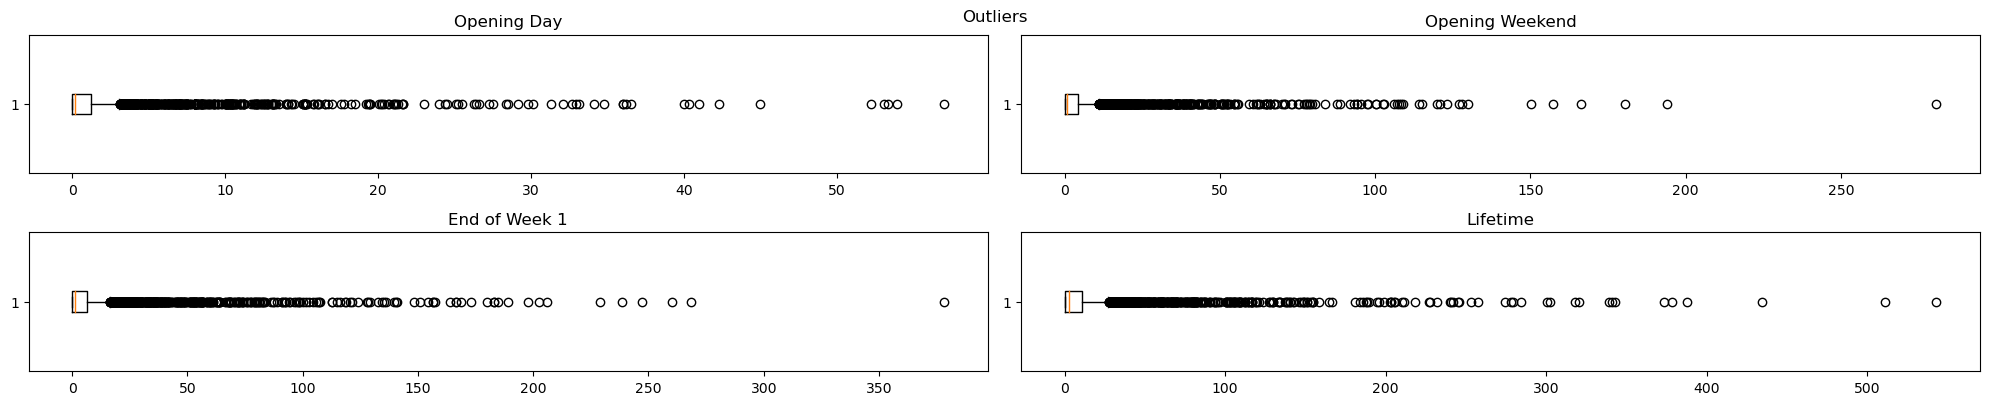

Total number of outliers in each column:
Opening Day : 472
Opening Weekend : 499
End of Week 1 : 506
Lifetime : 466

Ratio of outliers
Opening Day : 0.14
Opening Weekend : 0.15
End of Week 1 : 0.15
Lifetime : 0.14


In [6]:
# Copy
complete_df = df.copy()

# Drop rows with missing values in the 'Lifetime' column
complete_df.dropna(subset=['Lifetime'],inplace=True)
print(complete_df['Lifetime'].isnull().sum())

# Print the descriptive statistics of the DataFrame
print("Descriptive statistics of the DataFrame:")
print(complete_df.describe())

# Create a dictionary to store outlier information
out = {}

# Create a figure for boxplots of each column
plt.figure(figsize=(20, 20))

# Counter for subplot position
x = 1

# Add a title for the overall plot
plt.suptitle('Outliers')

# Iterate over the columns (starting from the third column)
for i, j in enumerate(complete_df.columns[2:]):
    # Create a subplot for each column
    plt.subplot(10, 2, x)
    
    # Generate the boxplot for the column and drop missing values
    box = plt.boxplot(complete_df[j].dropna(), vert=False)
    
    # Extract outlier values from the boxplot
    outlier = [item.get_ydata() for item in box['fliers']]
    
    # Store the outlier information in the dictionary
    out[j] = outlier
    
    # Set the title for the subplot
    plt.title(j)
    
    # Increment the counter for subplot position
    x += 1

# Adjust the layout and display the plot
plt.tight_layout()
plt.show()

# Print the total number of outliers in each column
print('Total number of outliers in each column:')
for key in out.keys():
    print(key, ':', len(out[key][0]))
    
print('\nRatio of outliers')
for key in out.keys():
    print(key, ':', round(len(out[key][0])/len(df),2))


**15% Noise in the Dataset**💢

In the given dataset, we are dealing with a situation where **15%** of the values contain noise. This level of missing data can have a significant impact on the accuracy and reliability of our analyses. To address this issue, we will employ the **Iterative Imputer**, a powerful technique for filling in missing values.

Unlike simple imputation methods like using mean or median values, the Iterative Imputer takes into account the relationships between different features in the dataset. It utilizes a **multivariate approach**, using the entire set of available features to estimate missing values. This allows for a more comprehensive and contextually informed imputation process.

Considering the specific nature of the movie dataset, there are likely relationships between different weeks, such as *opening day*, *opening weekend*, *end of week 1*, and *lifetime collections*. By leveraging the Iterative Imputer, we can capture these relationships and generate more accurate imputations, enhancing the quality of our data analysis.

It is important to note that relying solely on mean or median values would overlook the underlying patterns and correlations present in the dataset. By adopting the Iterative Imputer, we can make informed estimations based on the available data, leading to a more reliable and comprehensive representation of the missing values.

In [7]:
# Enable the Iterative Imputer
imp = IterativeImputer(max_iter=10, random_state=0)

# Select the columns with float data types for imputation
cleaning = complete_df.select_dtypes(float)

# Perform imputation on selected columns
imputed_data = imp.fit_transform(cleaning)
complete_df[['Opening Day', 'Opening Weekend', 'End of Week 1', 'Lifetime']] = pd.DataFrame(imputed_data, columns=cleaning.columns)
complete_df.dropna(inplace=True) #Added 9 missing value for super flop movies

# Check for remaining missing values
missing_values = complete_df.isnull().sum()
print(missing_values)


Movie Name         0
Release Date       0
Opening Day        0
Opening Weekend    0
End of Week 1      0
Lifetime           0
dtype: int64


In [8]:
complete_df[~complete_df.isnull()]

,Movie Name,Release Date,Opening Day,Opening Weekend,End of Week 1,Lifetime
0,Samadhi,1950-01-01,0.00,0.00,0.000,0.750
1,Babul,1950-01-01,0.00,0.00,0.000,0.700
2,Awaara,1951-01-01,0.00,0.00,0.000,1.250
3,Albela,1951-01-01,0.00,0.00,0.000,0.900
4,Baazi,1951-01-01,0.00,0.00,0.000,1.000
...,...,...,...,...,...,...
3400,Knock at the Cabin (English),2023-02-03,0.29,1.33,1.760,2.260
3401,Daman,2023-02-03,0.80,4.09,6.220,9.390
3402,The Woman King (English),2023-02-03,0.00,0.00,0.002,0.002
3403,The Whale (English),2023-02-03,1.00,3.20,4.050,4.650


# Insights

## Most Common Word in Movie Name

One of the interesting aspects to explore in the dataset is the occurrence of words in the movie names. By analyzing the movie names, we can gain insights into the most common words used in Bollywood movies.

In [9]:
# Remove punctuation and preprocess text
def cleaning_text(text):
    import re
    # Remove non-alphabetic characters
    text = re.sub("[^A-Za-z]+", " ", text).lower()
    # Remove numbers
    text = re.sub("[0-9]+", " ", text)
    words = []
    for word in text.split(" "):
        # Filter out short words
        if len(word) > 3:
            words.append(word)
    return " ".join(words)

# Create a copy of the DataFrame
CW_df = complete_df.copy()

# Apply the cleaning_text function to 'Movie Name' column
complete_df['Movie Name'] = complete_df['Movie Name'].apply(cleaning_text)

# Remove leading and trailing whitespace from 'Movie Name' column
complete_df['Movie Name'] = complete_df['Movie Name'].str.strip()

# Join the 'Movie Name' values into a single string
text = ' '.join(complete_df['Movie Name'])
len(text)

# Remove punctuation from the text
no_punc_text = text.translate(str.maketrans('', '', string.punctuation))
len(no_punc_text)

# Tokenization
text_tokens = word_tokenize(no_punc_text)
print(text_tokens[0:50])


['samadhi', 'babul', 'awaara', 'albela', 'baazi', 'deedar', 'jadoo', 'baiju', 'bawra', 'daag', 'jaal', 'anarkali', 'nagin', 'nastik', 'taxi', 'driver', 'uran', 'khatola', 'shree', 'jhanak', 'jhanak', 'payal', 'baje', 'azaad', 'rasta', 'mother', 'india', 'aankhen', 'barah', 'haath', 'naya', 'daur', 'pyaasa', 'chalti', 'naam', 'gaadi', 'madhumati', 'navrang', 'anari', 'paigham', 'mughal', 'azam', 'chaudhvin', 'chand', 'apna', 'preet', 'parai', 'kohinoor', 'barsaat', 'raat']


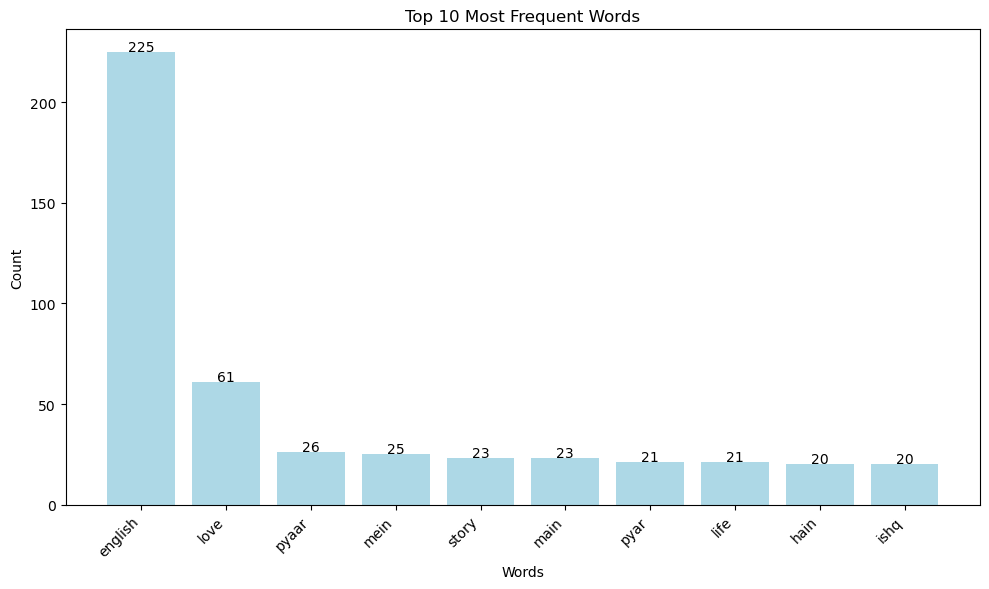

In [10]:
# Create an empty dictionary to store word counts
word_count = {}

# Count the occurrence of each word in the text_tokens list
for i in text_tokens:
    word_count[i] = text_tokens.count(i)

# Sort the word_count dictionary in descending order based on the word counts
sorted_dict = dict(sorted(word_count.items(), key=lambda x: x[1], reverse=True))

# Create a DataFrame from the word_count dictionary
df1 = pd.DataFrame(list(word_count.items()), columns=['Word', 'Count'])

# Sort the DataFrame based on the 'Count' column in descending order
df1.sort_values('Count', inplace=True, ascending=False)

# Plot a bar chart of the top 10 most frequent words
plt.figure(figsize=(10, 6))
plt.bar(df1['Word'][:10], df1['Count'][:10], color='lightblue')

plt.title('Top 10 Most Frequent Words')
plt.xlabel('Words')
plt.ylabel('Count')

# Add total count values on top of each bar
for i, count in enumerate(df1['Count'][:10]):
    plt.text(i, count + 0.5, str(count), ha='center')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

In [11]:
# Remove Stopwordsabs

# Define English and Hindi stopwords
english_stop_words = stopwords.words('english')
hindi_stop_words = ['apna', 'apni', 'apne', 'adi', 'aapka', 'aapki', 'aapke', 'ityadi', 'in', 'inka', 'inki', 'inke', 'inhi', 'inhe',
    'inhon', 'is', 'iska', 'iski', 'iske', 'ismein', 'issi', 'ise', 'un', 'unka', 'unki', 'unke', 'unko', 'unhi', 'unhe',
    'unhon', 'us', 'uske', 'usi', 'use', 'ek', 'evam', 'as', 'aise', 'aise', 'or', 'kai', 'kar', 'karta', 'karte', 'karna',
    'karne', 'karein', 'kahte', 'kaha', 'ka', 'kafi', 'kafi', 'ki', 'kitna', 'kinhen', 'kinhon', 'kiya', 'kir', 'kis', 'kisi',
    'kise', 'ki', 'kuch', 'kul', 'ke', 'ko', 'koi', 'kaun', 'kaunsa', 'gaya', 'ghar', 'jab', 'jahan', 'ja', 'jitna', 'jin', 'jinhen',
    'jinhon', 'jis', 'jise', 'jeetna', 'jo', 'tak', 'tab', 'tarah', 'tin', 'tinhin', 'tinhon', 'tis', 'tise', 'to', 'tha', 'thi', 'the',
    'dubara', 'diya', 'dusra', 'dusre', 'dusre', 'do', 'dvara', 'na', 'nahin', 'na', 'niche', 'ab', 'adik', 'aage', 'agar', 'ahi', 'ahin', 'aisa', 'aise', 'aisi', 'aitna', 'aitne', 'aitni', 'akela', 'akeli',
    'akle', 'ala', 'alag', 'anar', 'apana', 'apne', 'asal', 'asha', 'ashkar', 'ati', 'aur', 'bahar', 'bahut', 'bakar',
    'band', 'bane', 'banega', 'banegi', 'banenge', 'baneti', 'banni', 'bhae', 'bhar', 'bhari', 'bhaut', 'bhitar', 'bhuke',
    'bhukh', 'biwi', 'bolo', 'chahiye', 'chahye', 'chahu', 'chal', 'chalaa', 'chali', 'chale', 'chanchal', 'chanchalata',
    'chahta', 'chahti', 'chahun', 'char', 'chhod', 'chinta', 'chup', 'chupi', 'churaye', 'daud', 'dene', 'deta', 'deti',
    'detne', 'dhokha', 'dhund', 'doonga', 'doongi', 'dooge', 'doogi', 'doogo', 'dua', 'duaen', 'duniya', 'dusri', 'ekta',
    'gaya', 'ghare', 'guru', 'ham', 'hamari', 'hum', 'hume', 'hun', 'is', 'itna', 'itne', 'jaa', 'jaaiye', 'jaati', 'jaise',
    'jal', 'jale', 'jaruri', 'jat', 'jati', 'jeb', 'kaha', 'kab', 'kabhi', 'kahe', 'kahti', 'kahte', 'kaise', 'karti', 'karte',
    'karti', 'kartne', 'katne', 'khel', 'khela', 'kheli', 'khelo', 'kisi', 'kitne', 'koi', 'kom', 'kr', 'kuch', 'kudh', 'kyon',
    'lakho', 'li', 'lo', 'log', 'lota', 'mai', 'mar', 'mara', 'mari', 'marna', 'marne', 'mil', 'mila', 'milne', 'mujhe',
    'mujhse', 'na', 'naahi', 'naam', 'nai', 'naye', 'ne', 'ni', 'ni', 'nikle', 'par', 'pata', 'pate', 'pati', 'patne', 'ram',
    'raha', 'rahe', 'raho', 'ram', 'rasta', 'raste', 'saath', 'sab', 'sabse', 'sabke', 'sabki', 'sabka', 'sabko', 'sabhi',
    'sadi', 'sadi', 'sahab', 'sakta', 'sakti', 'sakte', 'samay', 'same', 'sara', 'sath', 'sau', 'sauda']

# Combine English and Hindi stopwords
my_stop_words = english_stop_words + hindi_stop_words
my_stop_words.append('english')  # Adding 'english' as a stop word

# Remove stopwords from the tokenized text
no_stop_tokens = [word for word in text_tokens if not word in my_stop_words]
print(f"""No stop tokens preview: 
{no_stop_tokens[0:40]}\n
Total Words After: {len(no_stop_tokens)}
Total Words Before: {len(text_tokens)}""")

# Normalize the data
lower_words = [word.lower() for word in no_stop_tokens]

print("\nNormalized Data:")
print(lower_words[0:25])


No stop tokens preview: 
['samadhi', 'babul', 'awaara', 'albela', 'baazi', 'deedar', 'jadoo', 'baiju', 'bawra', 'daag', 'jaal', 'anarkali', 'nagin', 'nastik', 'taxi', 'driver', 'uran', 'khatola', 'shree', 'jhanak', 'jhanak', 'payal', 'baje', 'azaad', 'mother', 'india', 'aankhen', 'barah', 'haath', 'naya', 'daur', 'pyaasa', 'chalti', 'gaadi', 'madhumati', 'navrang', 'anari', 'paigham', 'mughal', 'azam']

Total Words After: 5567
Total Words Before: 6038

Normalized Data:
['samadhi', 'babul', 'awaara', 'albela', 'baazi', 'deedar', 'jadoo', 'baiju', 'bawra', 'daag', 'jaal', 'anarkali', 'nagin', 'nastik', 'taxi', 'driver', 'uran', 'khatola', 'shree', 'jhanak', 'jhanak', 'payal', 'baje', 'azaad', 'mother']


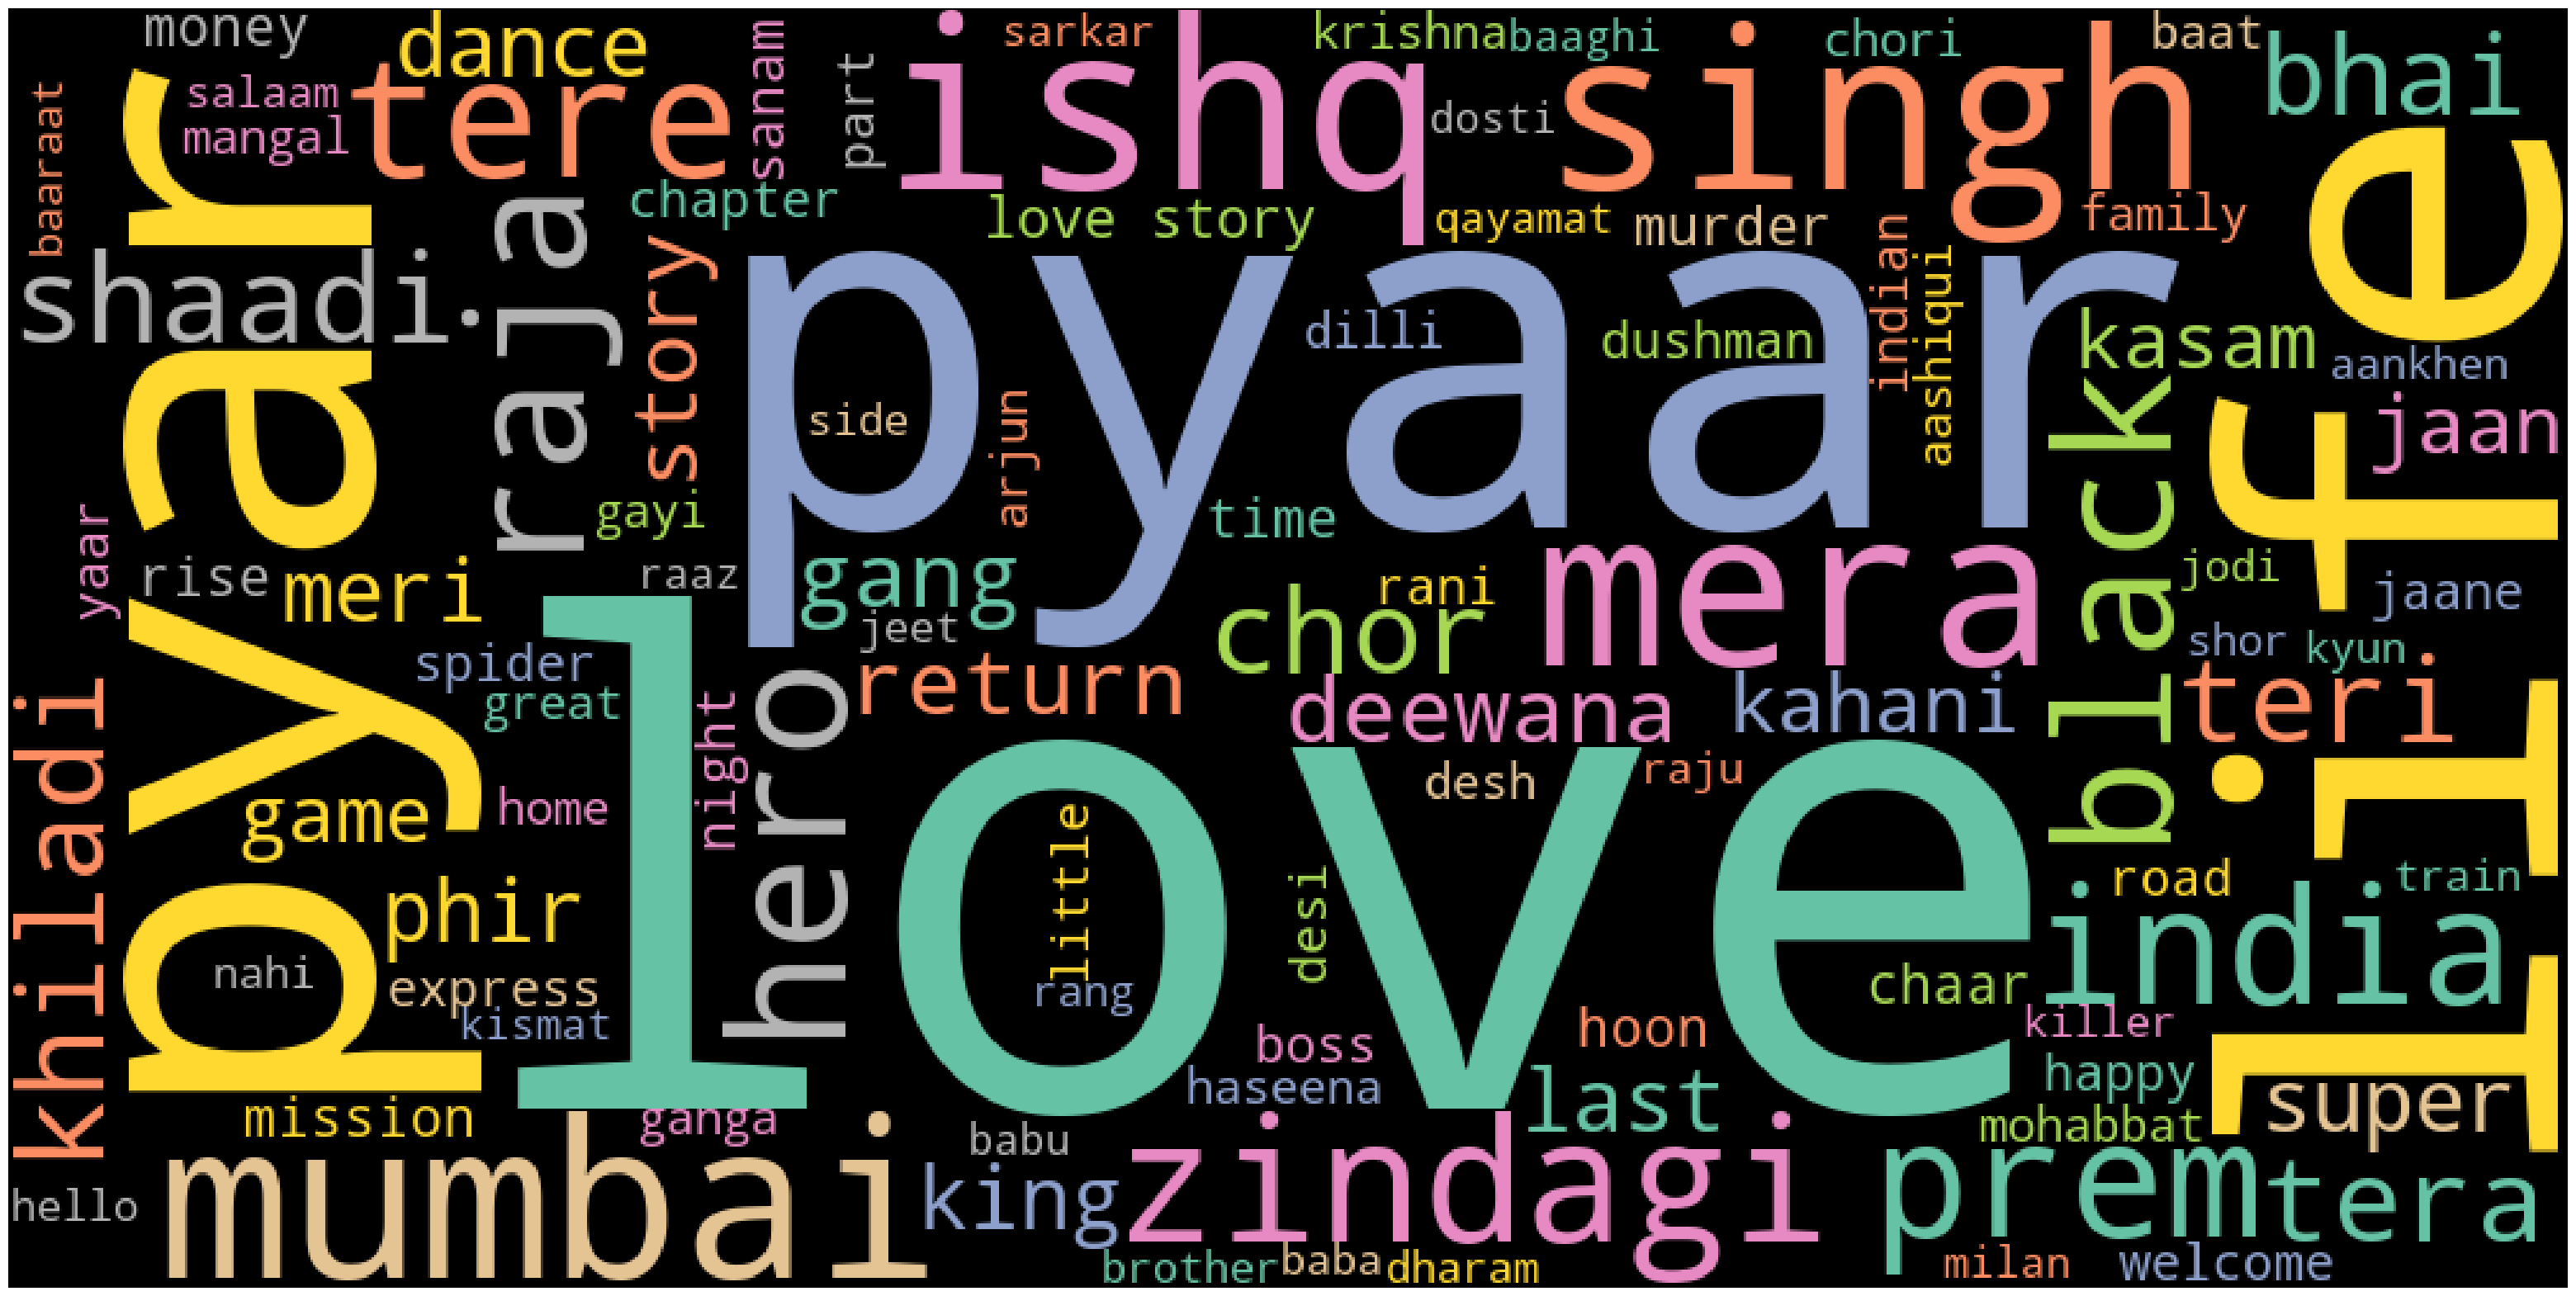

In [12]:
# Generate wordcloud


# Define a function to plot word cloud
def plot_cloud(wordcloud):
    # Set figure size
    plt.figure(figsize=(40, 30))
    # Display image
    plt.imshow(wordcloud) 
    # No axis details
    plt.axis("off");
    
stopwords = my_stop_words
my_stop_words.append('main')
my_stop_words.append('mein')
my_stop_words.append('hain')
my_stop_words.append('mere')

txt= " ".join(lower_words)

# update width and height for better cloud
wordcloud = WordCloud(width = 1000, height = 500, background_color='black', 
                      max_words=100,colormap='Set2',stopwords=stopwords).generate(txt)
# Plot
plot_cloud(wordcloud)

To determine the most common word, we performed a frequency analysis on the movie names column. We extracted individual words from each movie name and calculated the frequency of occurrence for each word. This analysis allows us to identify the words that are most frequently used in movie names.

The wordcloud analysis of the most common words used for Bollywood movies provides fascinating insights into the recurring themes and emotions prevalent in this dynamic industry. The prominence of the word "love" signifies its pivotal role as a fundamental element in Bollywood storytelling. It underscores the enduring appeal of romantic narratives and the emphasis on emotional connections within these movies.

The words "pyaar," "mein," "main," and "pyar" further reinforce the theme of love, depicting its expression and exploration from different perspectives. These words highlight the depth and complexity of relationships portrayed in Bollywood films.

Additionally, the inclusion of "story" reflects the significance of strong narratives in Bollywood cinema. It showcases the industry's commitment to engaging storytelling techniques that captivate audiences and leave a lasting impact.

Furthermore, words like "life," "hain," "mere," and "mera" shed light on the personal and relatable nature of Bollywood movies. These words evoke a sense of authenticity and enable viewers to connect with the characters and their experiences on a profound level.

Overall, this wordcloud analysis demonstrates the enduring popularity of love as a central theme in Bollywood movies. It also underscores the industry's focus on crafting compelling narratives that resonate with audiences and evoke powerful emotions. The presence of words related to personal perspectives and relatable experiences further enriches the cinematic landscape, making Bollywood films a source of both entertainment and emotional connection for viewers.

## Highest movie release date.

The highest movie release date in Bollywood holds significance as it reflects the competitive landscape and strategies employed by filmmakers. Analyzing this data allows us to observe trends in movie releases and their impact on factors like opening weekend collections and overall earnings. Insights gained from this analysis can inform decision-making for effective release strategies and maximize movie success.

In [13]:
df['Release Date'].describe()

count                    3414
unique                   1604
top       1972-01-01 00:00:00
freq                       19
first     1950-01-01 00:00:00
last      2023-06-29 00:00:00
Name: Release Date, dtype: object

The highest movie release date in the dataset is  "1972-01-01 00:00:00," which occurs most frequently among all the release dates. This indicates that the 1972-01-01 had the highest number of movie releases compared to other years within the given dataset.

In [14]:
most_released_day = df['Release Date'].mode()[0]
most_released_day

Timestamp('1972-01-01 00:00:00')

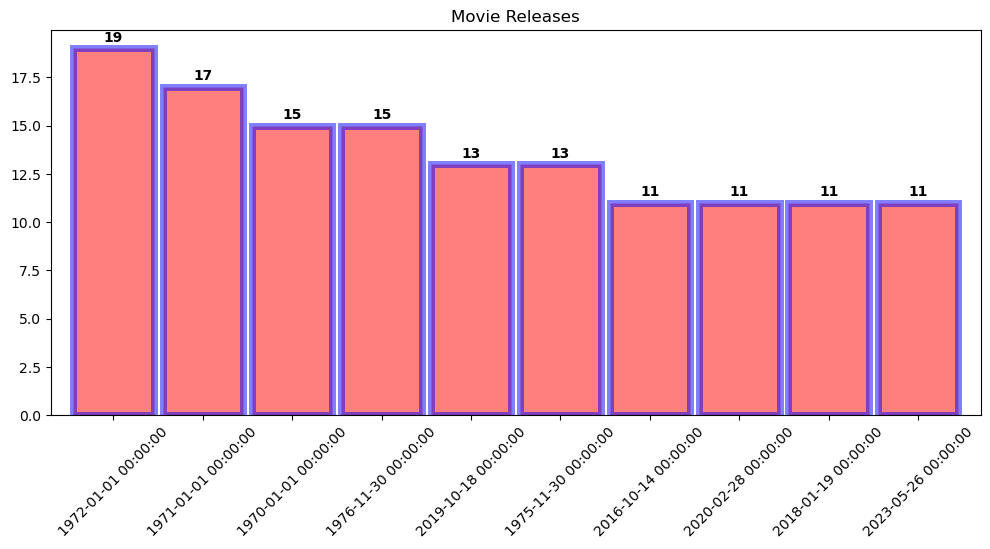

In [15]:
# Count the number of movie releases for each date
date_counts = df['Release Date'].value_counts().head(10)

# Create the bar plot
fig, ax = plt.subplots()
bar_plot = date_counts.plot(kind='bar', color='red', alpha=0.5, width=0.9, edgecolor='blue', linewidth=5,figsize=(12,5))

# Add the total count as text on top of each bar
for i, count in enumerate(date_counts):
    ax.text(i, count + .2, str(count), ha='center', va='bottom', fontsize=10, fontweight='bold')

# Set the title of the plot
plt.title('Movie Releases')

# Rotate the x-axis tick labels for better readability
plt.xticks(rotation=45)

# Display the plot
plt.show()


The analysis of the dataset reveals an interesting pattern in the movie release dates, particularly with the top three highest release dates: "1972-01-01", "1971-01-01", and "1970-01-01". These dates consistently stand out as the most prevalent release dates during their respective years, with 19, 17, and 15 movie releases, respectively.

## Highest Opening Weekend.


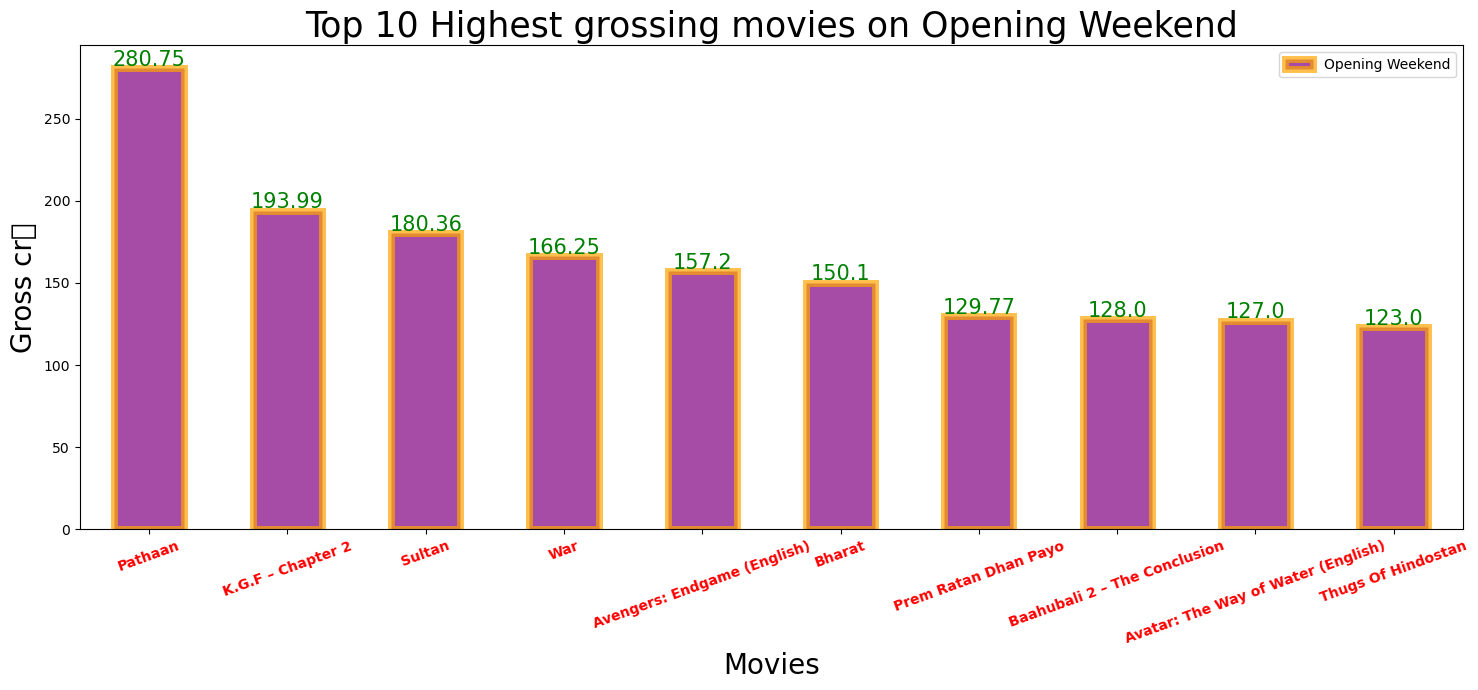

In [16]:
# Highest Opening Weekend: how
how = df.copy()

how.sort_values('Opening Weekend',ascending=False,inplace=True)
how.head()


# Plot the barhart
x = how[['Movie Name','Opening Weekend']].head(10).set_index('Movie Name')
x.plot(kind='bar', color='purple', alpha=0.7,edgecolor='orange',linewidth=5,figsize=(15,7))

# Set the title and axis labels
plt.title('Top 10 Highest grossing movies on Opening Weekend',fontsize=25)
plt.xlabel('Movies',fontsize=20)
plt.ylabel('Gross cr💸',fontsize=20)

# Add value labels on top of each bar
for i, value in enumerate(how['Opening Weekend'].head(10)):
    plt.text(i, value + 1.5, str(value), ha='center',color='green',fontsize=15)

# Rotate x-axis labels if needed
plt.xticks(rotation=20,color='red',fontweight='bold')

# Show the plot
plt.tight_layout()
plt.show()

1. `Pathaan`: Breaking Records and Setting New Benchmarks
Pathaan emerges as an undisputed champion, showcasing a staggering opening weekend collection of **280.75** million. With its gripping narrative, charismatic performances, and masterful direction, Pathaan has captivated audiences, leaving an indelible mark on the box office landscape.

2. `K.G.F` – Chapter 2: A Saga of Epic Proportions
K.G.F – Chapter 2 stands tall with a remarkable opening weekend collection of **193.99 million**. This highly anticipated sequel has not only met but surpassed sky-high expectations, creating a cinematic spectacle that has left audiences awestruck and hungry for more.

3. `Sultan`: A Triumph of Sports Drama
Sultan takes the third spot, flexing its muscles with an impressive opening weekend collection of **180.36 million**. This adrenaline-fueled sports drama, infused with emotion and power-packed performances, has struck a chord with viewers, delivering a knockout punch at the box office.

4. `War`: Explosive Action Unleashed
War unleashes its cinematic firepower, amassing a commendable opening weekend collection of **166.25 million**. With its heart-racing action sequences, high production values, and a clash of charismatic stars, War has emerged as a true crowd-pleaser, leaving audiences craving more adrenaline-pumping thrills.

5. `Avengers`: Endgame (English): A Global Phenomenon
Avengers: Endgame (English) defies language barriers, conquering hearts and wallets with a compelling opening weekend collection of **157.20 million**. This superhero extravaganza, crafted with precision and grandeur, has etched its name in history, demonstrating the boundless appeal of the Marvel Cinematic Universe.


In [17]:
del(how)

## No. of release on a day impacts opening weekend/Day.

<p style=color:green;font-size:15px;padding:5px;font-weight:bolder>Let's find out that - releasing more movies on a specific day leads to a shared budget and lower overall gross❓

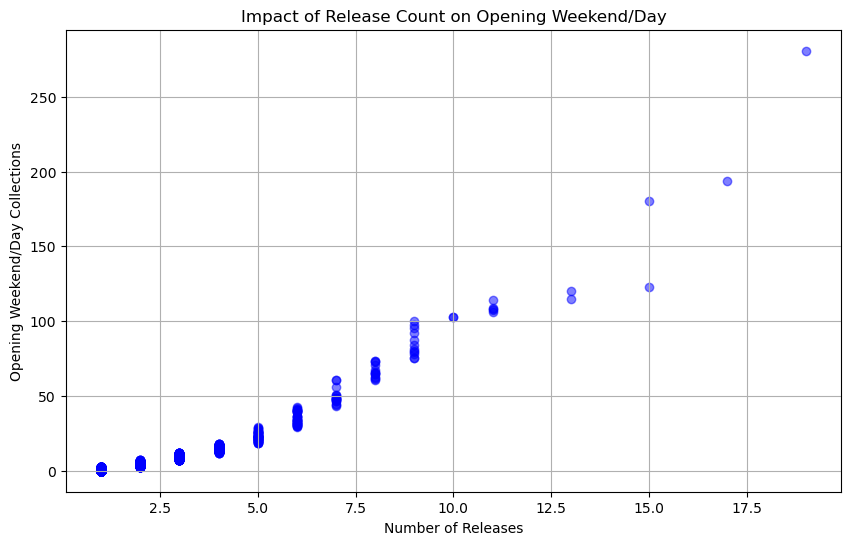

In [18]:

# Group the dataset by the release date and calculate the count of movie releases
release_counts = df.groupby('Release Date')['Movie Name'].count().sort_values(ascending=False)

# Group the dataset by the release date and calculate the average opening weekend/day collections
opening_avg = df.groupby('Release Date')['Opening Weekend'].mean().sort_values(ascending=False)

# Create a scatter plot to visualize the relationship between release count and opening weekend/day collections
plt.figure(figsize=(10, 6))
plt.scatter(release_counts, opening_avg, color='blue', alpha=0.5)
plt.xlabel('Number of Releases')
plt.ylabel('Opening Weekend/Day Collections')
plt.title('Impact of Release Count on Opening Weekend/Day')
plt.grid(True)

# Show the plot
plt.show()


Surprisingly, the scatter plot tells a different story. It shows that there isn't a clear connection between the number of movie releases and the overall gross collections. The scattered data points indicate that the relationship is not as straightforward as commonly believed.

This finding challenges the notion that having more movies released on a particular day automatically means a shared budget and lower overall gross. It suggests that factors other than the number of releases, such as the movie's content, marketing strategies, and audience reception, have a more significant impact on box office success.

So, it's important to consider these additional factors when analyzing the influence on overall gross collections. This analysis reminds us that the movie industry is complex, and it's essential to dig deeper to uncover the true dynamics at play.

## Top movies

In [19]:
# Group the dataset by movie names
grouped_data = df.groupby('Movie Name')

# Calculate summary statistics for each group
summary_stats = grouped_data.agg({
    'Opening Weekend': 'mean',
    'End of Week 1': 'mean',
    'Lifetime': 'mean'
})

# Sort the summary statistics by a specific financial metric (e.g., Opening Weekend)
sorted_stats = summary_stats.sort_values('Opening Weekend', ascending=False)

# Print the sorted summary statistics
print(sorted_stats)

                             Opening Weekend  End of Week 1  Lifetime
Movie Name                                                           
Pathaan                               280.75         378.15    543.05
K.G.F – Chapter 2                     193.99         268.63    434.70
Sultan                                180.36         229.16    300.45
War                                   166.25         238.35    317.91
Avengers: Endgame (English)           157.20         260.40    373.22
...                                      ...            ...       ...
Yeh Jo Mohabbat Hai                      NaN           0.22      0.26
Yeh Khula Aasmaan                        NaN           0.23      0.29
Zed Plus                                 NaN           0.47      0.47
Zindagi Tere Naam                        NaN           0.03      0.04
Zokkomon                                 NaN            NaN      0.61

[3338 rows x 3 columns]


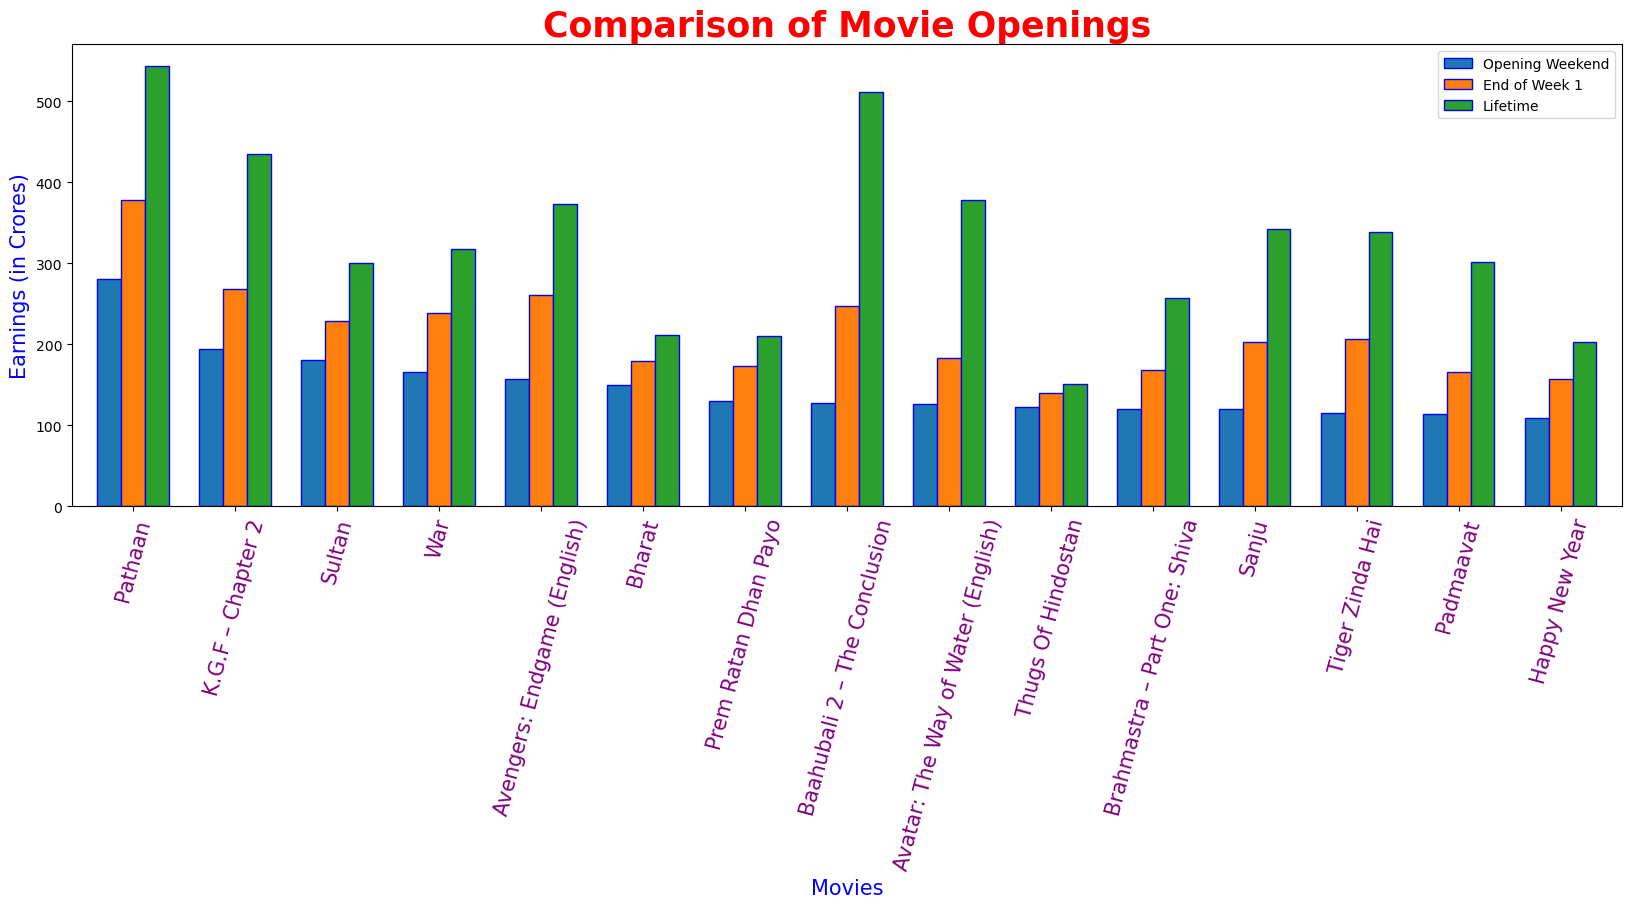

In [20]:
# Select the top 15 movies for comparison
top_movies = sorted_stats[:15]

# Create the bar plot with customized settings
top_movies.plot(kind='bar', figsize=(20, 6), width=0.7, alpha=1,edgecolor='blue' )

# Customize the x-axis labels
plt.xticks(rotation=75, color='purple', fontsize=15)

# Add title and axis labels
plt.title('Comparison of Movie Openings', fontsize=25, color='red', fontweight='bold', fontfamily='Comic Sans MS')
plt.xlabel('Movies', fontsize=15, color='blue')
plt.ylabel('Earnings (in Crores)', fontsize=15, color='blue')

# Display the plot
plt.show()


## Does Words in Movie impacts earnings.
Analyzing whether the movie name impacts earnings is an intriguing question in the context of Bollywood movies. The movie name plays a crucial role in attracting audiences and generating interest, which in turn can influence the earnings of a film. However, determining the direct impact of the movie name on earnings requires a more comprehensive analysis.

To investigate this, we can explore correlations between the movie name and financial metrics such as opening day collections, opening weekend collections, end of week 1 earnings, and lifetime earnings. By examining the relationship between the movie name and these financial indicators, we can gain insights into whether certain types of names tend to perform better in terms of earnings.

### Calculate the correlations between the movie name and financial metrics:

In [21]:
# Create a word frequency dictionary
word_freq = {}

# Iterate through movie names
for movie_name in txt.split():
    # Split movie name into words
    words = movie_name.split()
    # Update word frequency dictionary
    for word in words:
        word_freq[word] = word_freq.get(word, 0) + 1

# Calculate total opening weekend for each word
word_opening_weekend = {}
for word in word_freq.keys():
    try:
        total_opening_weekend = df[df['Movie Name'].str.contains(word, case=False)]['Opening Weekend'].sum()
        word_opening_weekend[word] = total_opening_weekend
    except:
        pass
# Sort words by total opening weekend in descending order
sorted_words = sorted(word_opening_weekend, key=word_opening_weekend.get, reverse=True)

# Assign rank to each word
word_rank = {word: rank + 1 for rank, word in enumerate(sorted_words)}

# Print the word ranks
for word, rank in word_rank.items():
    print(f"{word}: Rank {rank}")

haan: Rank 1
sing: Rank 2
jaan: Rank 3
singh: Rank 4
bang: Rank 5
avengers: Rank 6
mast: Rank 7
maal: Rank 8
rang: Rank 9
chapter: Rank 10
return: Rank 11
turn: Rank 12
returns: Rank 13
house: Rank 14
story: Rank 15
tiger: Rank 16
prem: Rank 17
dhan: Rank 18
part: Rank 19
bhai: Rank 20
home: Rank 21
spider: Rank 22
dabangg: Rank 23
yaar: Rank 24
year: Rank 25
zinda: Rank 26
race: Rank 27
sultan: Rank 28
love: Rank 29
housefull: Rank 30
miss: Rank 31
bali: Rank 32
mission: Rank 33
baaghi: Rank 34
game: Rank 35
hero: Rank 36
pyaar: Rank 37
endgame: Rank 38
body: Rank 39
mangal: Rank 40
main: Rank 41
shiva: Rank 42
shiv: Rank 43
bharat: Rank 44
dost: Rank 45
golmaal: Rank 46
super: Rank 47
happy: Rank 48
thor: Rank 49
fast: Rank 50
dhoom: Rank 51
ratan: Rank 52
payo: Rank 53
baahubali: Rank 54
conclusion: Rank 55
water: Rank 56
avatar: Rank 57
daar: Rank 58
thug: Rank 59
thugs: Rank 60
hindostan: Rank 61
gang: Rank 62
guard: Rank 63
brahmastra: Rank 64
sanju: Rank 65
king: Rank 66
bach: R

In [22]:
# no_stop_tokensL Using it from Wordcloud.

wf = {} #Word Frequency 

for i in no_stop_tokens:
    wf[i]=no_stop_tokens.count(i)
    
sorted_wf=dict(sorted(wf.items(), key=lambda x: x[1],reverse=True))

df1=pd.DataFrame(sorted_wf.items(),columns=['word','frequency'])

df1.head(1)

,word,frequency
0,love,61


In [23]:
# Create an empty dictionary to store movie earnings for each word
counter = {}
total = {}
avg = {}
# Iterate over each token in the 'word' column of DataFrame df1
for token in df1['word']:
    # Initialize an empty list for each token in the counter dictionary
    counter[token] = []
    
    # Iterate over each index and corresponding movie in the 'Movie Name' column of DataFrame df
    for index, movie in enumerate(complete_df['Movie Name']):
        
        # Avoid Null Values
        try:
            # Check if the token is present in the movie name
            if token in movie:
                # Append the corresponding 'Lifetime' earnings to the counter[token] list
                counter[token].append(complete_df['Lifetime'][index])
        except:
            pass
    total[token]=(sum(counter[token]))
    try:
        avg[token]=sum(counter[token])/len(counter[token])
    except:
        pass

# print(counter,total,avg)

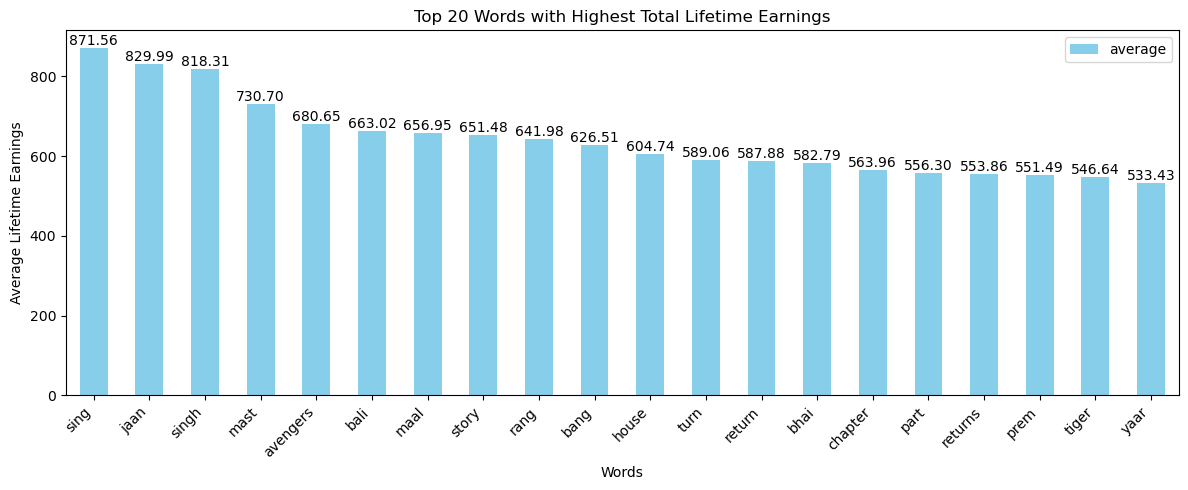

In [24]:
# Total Name Gross
total_df=pd.DataFrame(total.items(),columns=['word','average']).set_index('word')
total_df.sort_values('average',ascending=False,inplace=True)


# Set the figure size and create a bar plot

bars = total_df.head(20).plot(kind='bar', color='skyblue',figsize=(12, 5))

# Set the plot title, x-axis label, and y-axis label
plt.title('Top 20 Words with Highest Total Lifetime Earnings')
plt.xlabel('Words')
plt.ylabel('Average Lifetime Earnings')

# Rotate the x-axis labels for better readability
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for bar in bars.patches:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{height:.2f}', ha='center', va='bottom')

# Show the plot
plt.tight_layout()
plt.show()

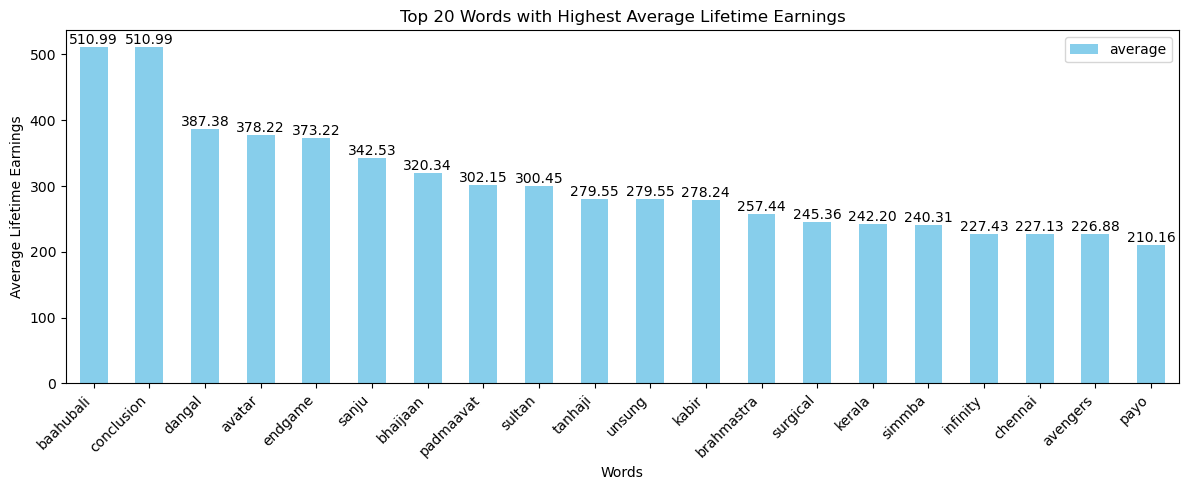

In [25]:
# Avg name gross
avg_df=pd.DataFrame(avg.items(),columns=['word','average']).set_index('word')
avg_df.sort_values('average',ascending=False,inplace=True)


# Set the figure size and create a bar plot

bars = avg_df.head(20).plot(kind='bar', color='skyblue',figsize=(12, 5))

# Set the plot title, x-axis label, and y-axis label
plt.title('Top 20 Words with Highest Average Lifetime Earnings')
plt.xlabel('Words')
plt.ylabel('Average Lifetime Earnings')

# Rotate the x-axis labels for better readability
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for bar in bars.patches:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{height:.2f}', ha='center', va='bottom')

# Show the plot
plt.tight_layout()
plt.show()

In [26]:
# Initialize variables to track the maximum length and corresponding key
maximum_length = 0
value = None

# Find the key with the maximum length of movie earnings
for i in counter.keys():
    length = len(counter[i])
    if length > maximum_length:
        maximum_length = length
        value = i

# Adjust the length of movie earnings lists for each key to match the maximum length
for i in counter.keys():
    length = len(counter[i])
    if length <= maximum_length:
        difference = maximum_length - length
        # Create a list of zeros to extend the movie earnings list
        zeros = [0] * difference
        counter[i].extend(zeros)

# Create a DataFrame from the counter dictionary
df1 = pd.DataFrame(counter)


df1.iloc[:10,:10]

,love,pyaar,mein,main,story,pyar,life,hain,ishq,mere
0,1.75,7.26,2.25,1.45,5.75,2.20,5.84,1.25,24.93,3.00
1,5.75,21.51,1.70,0.82,6.99,4.50,15.83,5.00,3.32,3.50
2,6.99,6.80,1.50,2.75,4.84,14.00,20.67,3.02,7.74,0.85
3,5.57,1.86,1.86,2.50,2.90,5.00,1.65,72.47,22.68,0.85
4,17.78,6.70,17.03,14.00,11.01,1.76,0.05,39.18,47.09,0.48
5,4.84,15.28,7.03,7.88,43.17,11.71,1.09,6.24,28.55,7.71
6,15.94,44.28,5.52,6.20,4.11,18.07,61.00,17.03,25.50,2.92
7,3.47,7.76,17.51,7.95,0.06,10.07,0.32,13.52,27.50,11.65
8,2.90,3.32,1.65,6.40,13.55,3.42,0.05,0.03,0.04,8.34
9,11.01,6.83,0.03,8.93,4.94,2.37,0.04,0.07,0.04,3.80


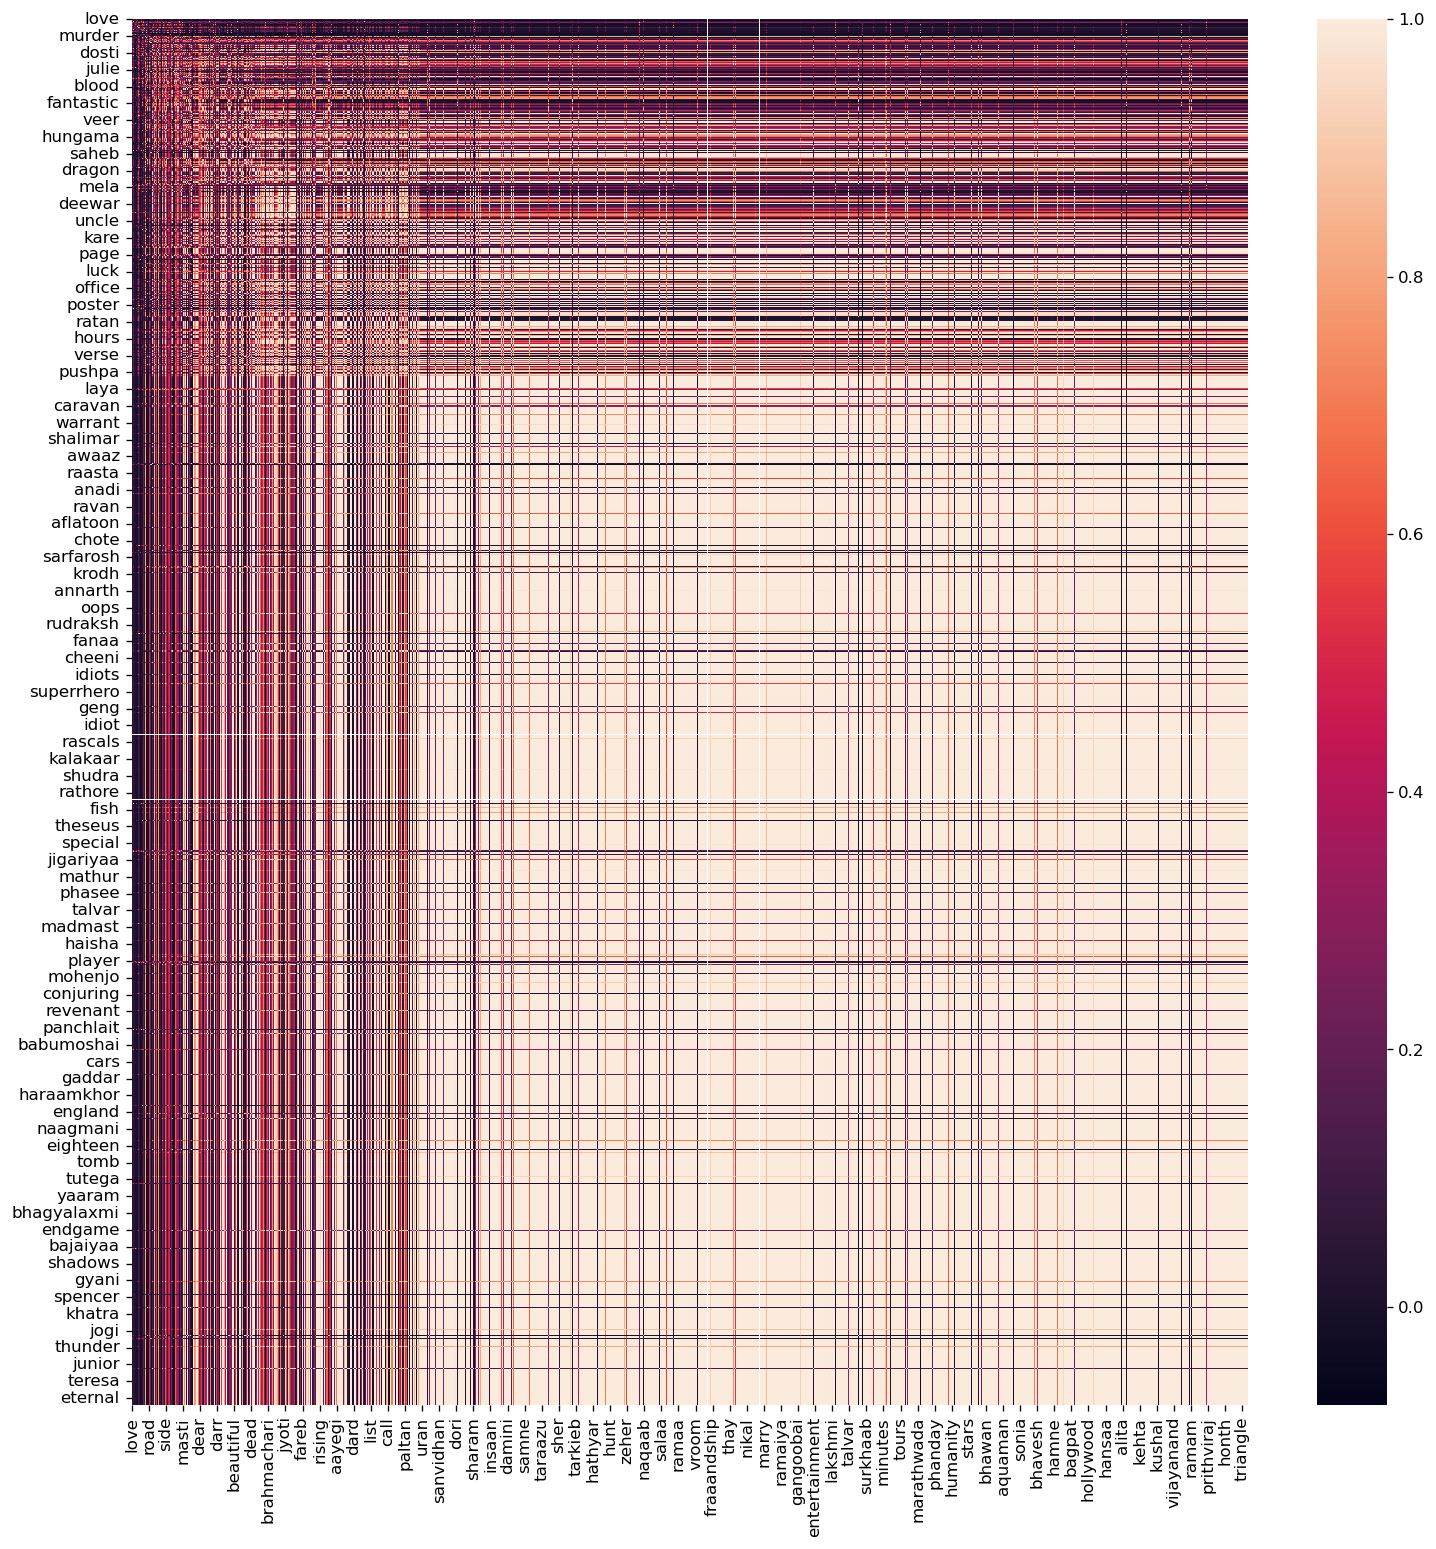

In [27]:
# Corr
corr=df1.corr()

subset = corr[corr > 0.65]

# Print the subset
# print(subset)

plt.figure(dpi=120,figsize = (15,15))
sns.heatmap(corr)

plt.savefig('corr_earning.png')

plt.show()

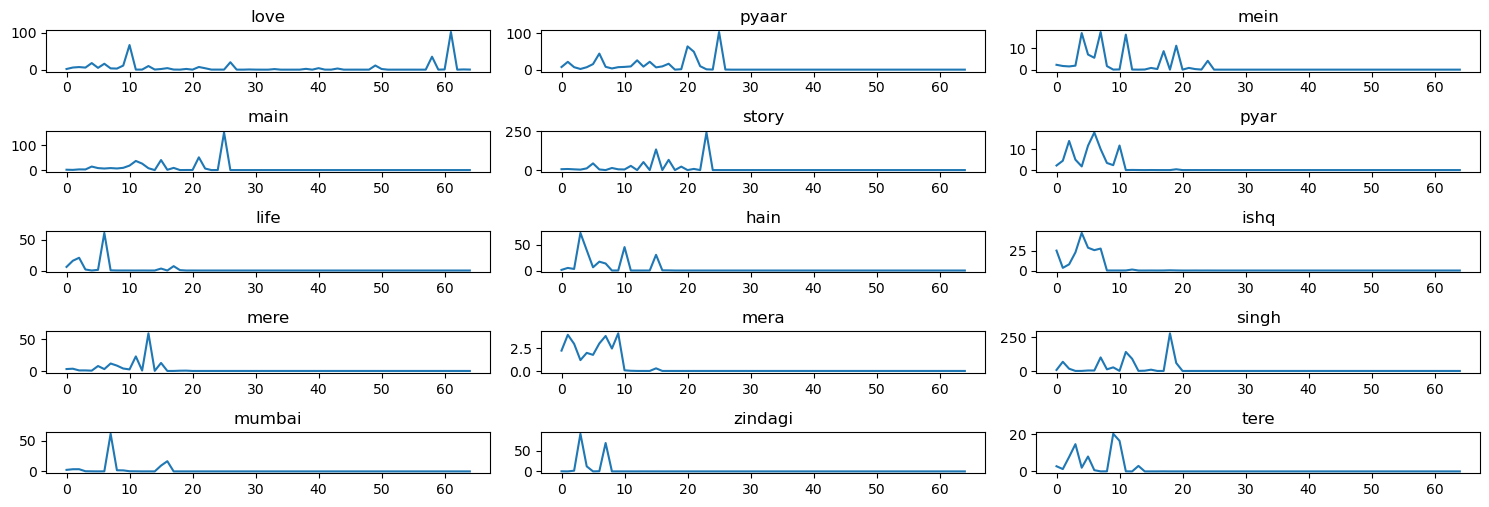

In [28]:
plt.figure(figsize=(15,20))

for i in range(15):
    plt.subplot(20,3,i+1)
    col = df1.columns[i]
    plt.plot(df1[col])
    plt.title(col)
    
plt.tight_layout()
plt.show()

- Corelation shows an unidentified pattern between the gross of the words.


### Hypothesis Testing

#### 

****Null Hypothesis****: The presence of Word has no significant effect on movie earnings.

****Alternative Hypothesis****: The presence of Word has a significant effect on movie earnings

In [29]:
# Test - 1 Lifetime
valuable_words1 = []
for movie in total_df.index:
    # Extract the movie earnings for movies with and without Word A
    movies_with_word_a = complete_df[complete_df['Movie Name'].str.contains(movie)]['Lifetime']
    movies_without_word_a = complete_df[~complete_df['Movie Name'].str.contains(movie)]['Lifetime']

    # Perform t-test
    t_stat, p_value = stats.ttest_ind(movies_with_word_a, movies_without_word_a)

    # Check the significance level
    alpha = 0.05
    if p_value < alpha:
        valuable_words1.append(movie)

if bool(valuable_words1):
    print(f'Words have impact on Lifetime Movie Income\n{valuable_words1}')
else:
    print('Words have no impact on Life Movie Income')

Words have impact on Lifetime Movie Income
['dhoom', 'miss', 'mission', 'mangal', 'come', 'dance', 'welcome', 'idiot', 'verse', 'anna', 'weds', 'impossible', 'light', 'never', 'hasee', 'akbar', 'murder', 'justice', 'kingdom', 'sarkar', 'heropanti', 'nation', 'zameen', 'hota', 'haseen', 'last', 'saab', 'blue', 'patiala', 'adhuri', 'live', 'malamaal', 'family', 'natwarlal', 'haseena', 'shaukeen', 'angry', 'major', 'rings', 'paas', 'magic', 'desh', 'huye', 'real', 'shaheed', 'shikhar', 'spiderman', 'dangerous', 'andolan', 'mall', 'flat', 'passion', 'tutiya', 'paisa', 'resident', 'anand', 'tell', 'shankar', 'grace', 'chala', 'crazy', 'jean', 'search', 'middle', 'kaagaz', 'vivek', 'kaisa', 'relation']


In [30]:
# Test - 2 Opening Day
valuable_words2 = []
for movie in total_df.index:
    # Extract the movie earnings for movies with and without Word A
    movies_with_word_a = complete_df[complete_df['Movie Name'].str.contains(movie)]['Opening Day']
    movies_without_word_a = complete_df[~complete_df['Movie Name'].str.contains(movie)]['Opening Day']

    # Perform t-test
    t_stat, p_value = stats.ttest_ind(movies_with_word_a, movies_without_word_a)

    # Check the significance level
    alpha = 0.05
    if p_value < alpha:
        valuable_words2.append(movie)


if bool(valuable_words2):
    print(f'Words have impact on Opening Day Movie Income\nValuable Words: {valuable_words2}')
else:
    print('Words have no impact on Opening Day Movie Income')

Words have impact on Opening Day Movie Income
Valuable Words: ['sing', 'singh', 'avengers', 'race', 'mangal', 'come', 'dance', 'welcome', 'stree', 'verse', 'anna', 'weds', 'tanu', 'impossible', 'light', 'never', 'akbar', 'mein', 'murder', 'sanam', 'sarkar', 'nation', 'punchnama', 'last', 'romeo', 'ishaq', 'saab', 'blue', 'adhuri', 'loot', 'natwarlal', 'indian', 'angry', 'magic', 'thoda', 'talkies', 'club', 'shikhar', 'four', 'spiderman', 'andolan', 'mall', 'gali', 'tutiya', 'paisa', 'resident', 'anand', 'grace', 'chala', 'crazy', 'jean', 'kaagaz', 'vivek', 'walking', 'kaisa', 'relation', 'twist', 'bazaar']


In [31]:
# Test - 3 End of Week 1
valuable_words3 = []
for movie in total_df.index:
    # Extract the movie earnings for movies with and without Word
    movies_with_word_a = complete_df[complete_df['Movie Name'].str.contains(movie)]['End of Week 1']
    movies_without_word_a = complete_df[~complete_df['Movie Name'].str.contains(movie)]['End of Week 1']

    # Perform t-test
    t_stat, p_value = stats.ttest_ind(movies_with_word_a, movies_without_word_a)

    # Check the significance level
    alpha = 0.05
    if p_value < alpha:
        valuable_words3.append(movie)


if bool(valuable_words3):
    print(f'Words have impact on End of Week 1 Movie Income\nValuable Words: {valuable_words3}')
else:
    print('Words have no impact on End of Week 1 Movie Income')

Words have impact on End of Week 1 Movie Income
Valuable Words: ['sing', 'singh', 'avengers', 'miss', 'mission', 'race', 'mangal', 'come', 'dance', 'welcome', 'verse', 'anna', 'weds', 'barfi', 'impossible', 'light', 'never', 'hasee', 'akbar', 'talaash', 'mein', 'murder', 'justice', 'sarkar', 'heropanti', 'nation', 'zameen', 'hota', 'haseen', 'galaxy', 'great', 'last', 'ishaq', 'saab', 'blue', 'adhuri', 'live', 'loot', 'family', 'natwarlal', 'haseena', 'angry', 'major', 'magic', 'thoda', 'shaheed', 'club', 'shikhar', 'spiderman', 'dangerous', 'andolan', 'mall', 'gali', 'tutiya', 'paisa', 'resident', 'kahin', 'anand', 'tell', 'shankar', 'grace', 'chala', 'crazy', 'jean', 'kaagaz', 'vivek', 'kaisa', 'relation', 'twist']


In [32]:
Lifetime = set(valuable_words1)
od = set(valuable_words2)
eow = set(valuable_words3)

Most Valuable words: {'mangal', 'dance', 'mall', 'come', 'kaisa', 'weds', 'adhuri', 'akbar', 'resident', 'relation', 'verse', 'anna', 'chala', 'never', 'spiderman', 'last', 'crazy', 'andolan', 'kaagaz', 'anand', 'magic', 'light', 'welcome', 'angry', 'blue', 'jean', 'murder', 'tutiya', 'grace', 'natwarlal', 'nation', 'sarkar', 'paisa', 'vivek', 'impossible', 'shikhar', 'saab'}


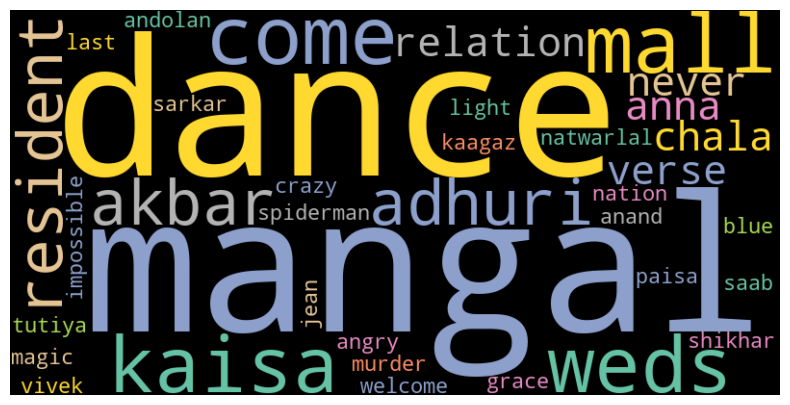

In [33]:
MVw = Lifetime.intersection(od,eow)

print(f"Most Valuable words: {MVw}")
# Create a WordCloud object
wordcloud = WordCloud(width=800, height=400, background_color='black',colormap='Set2').generate(' '.join(MVw))

# Plot the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

# Remaining Questions

1. Identify abnormal Earnings
5. Average opening day collections.
6. Average lifetime collections.
7. Movie with the highest lifetime collections.
8. Movie with the lowest lifetime collections.
9. Average collections at the end of week 1.
10. Average opening weekend collections.
11. Distribution of movie releases by year.
12. Analysis of movie releases by month or season.
13. Correlation between opening weekend collections and end of week 1 collections.
14. Trends in movie releases and collections over the years.
15. Seasonal trends: Analyze if there are any patterns or trends in movie releases and collections based on seasons or specific months of the year. For example, do movies released during the holiday season tend to have higher collections?
16. Comparison of opening weekend collections: Identify the top movies with the highest opening weekend collections and compare their performance. Is there any common factor among these movies that contributes to their success?
17. Release day impact: Analyze whether the day of the week on which a movie is released has any impact on its opening weekend collections. For example, do movies released on Fridays perform better compared to other days?
18. Average collections per year: Calculate the average collections per year and observe if there are any significant fluctuations or growth trends over time.
19. Genre analysis: If available in your dataset, explore the impact of movie genres on their earnings. Do certain genres tend to have higher lifetime collections or perform better in the opening weekend?
20. Length of movies: Investigate if the duration of a movie influences its performance at the box office. Is there a correlation between movie length and opening weekend or lifetime collections?
21. Impact of critical reception: If available, consider incorporating movie ratings or critical reception data into your analysis. Determine whether movies with higher ratings or positive reviews tend to have higher collections.
22. Comparative analysis by decade: Group the movies by decade and compare their average collections, opening weekends, or any other relevant metric. Analyze whether there are any noticeable differences or trends between different decades.